# Data Science Case Studies

**Course:** Fundamentals of Data Science (22CSC59)

| | |
|---|---|
| **Name** | Sarapu Rushil |
| **Roll No** | 160124733197 |
| **Section** | CSE-3 |
| **Year** | III Year / V Semester |
| **Faculty** | S. Durga Devi, Assistant Professor |

This notebook contains two independent case studies:

| Part | Case study | Techniques |
|---|---|---|
| **A** | Titanic Survival Prediction using Logistic Regression | EDA, imputation, encoding, logistic regression, ROC-AUC, coefficient interpretation, Streamlit deployment |
| **B** | Comparative Analysis of Classification Algorithms for Bank Marketing Prediction | EDA, preprocessing, Logistic Regression, Decision Tree, KNN, Random Forest, model comparison, business recommendations |

**How to run:** use *Kernel → Restart & Run All*. The setup cell below must run first; after that, Part A and Part B are
independent — all variables are prefixed with `titanic_` or `bank_` so the two parts never overwrite each other.

## Setup (shared by both parts)
**Purpose:** import every library used in the notebook, define the folder locations and a helper to save figures.
All paths are relative to this notebook, so the project folder can be moved or uploaded to GitHub as a whole.

| Folder | Contents |
|---|---|
| `data/` | `titanic.csv`, `bank-additional-full.csv` |
| `figures/titanic/`, `figures/bank/` | Every plot produced by Part A and Part B |
| `model/` | Saved Titanic model and the metrics of both parts (used by the Streamlit app and the report) |

In [1]:
import warnings
import json
from pathlib import Path

# Core data libraries
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# ML utilities
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report,
)
import statsmodels.api as sm

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", palette="muted")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 15
SEED = RANDOM_STATE  # random state used throughout

# Directory layout
DATA_DIR   = Path("data")
FIG_DIR    = Path("figures")
MODEL_DIR  = Path("model")
for _dir in [FIG_DIR / "titanic", FIG_DIR / "bank", MODEL_DIR]:
    _dir.mkdir(parents=True, exist_ok=True)

def save(fig, part, name):
    """Save a figure as figures/<part>/<part>_<name>.png so it can be reused in the report."""
    fig.savefig(FIG_DIR / part / f"{part}_{name}.png", bbox_inches="tight", dpi=150)

save_figure = save  # alias

# Verify data files are present
csv_files = sorted(p.name for p in DATA_DIR.glob("*.csv"))
print("CSV files found:", csv_files)

CSV files found: ['bank-additional-full.csv', 'titanic.csv']


# Part A – Titanic Survival Prediction using Logistic Regression

## Problem Statement
On 15 April 1912 the RMS Titanic sank after hitting an iceberg; 1,502 of 2,224 passengers and crew died.
Survival was not random — factors such as gender, age and ticket class influenced who got a place on a lifeboat.

**Goal:** build a binary classification model that predicts whether a passenger **survived (1)** or **did not survive (0)**
from their personal and ticket details, interpret which factors matter most, and deploy the model as an interactive Streamlit app.

## Methodology
1. **Data Exploration** – load the data, inspect types, summary statistics and visualise distributions/relationships.
2. **Data Preprocessing** – handle missing values (imputation) and encode categorical variables.
3. **Model Building** – train a Logistic Regression model with scikit-learn on an 80/20 stratified train/test split.
4. **Model Evaluation** – accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix and ROC curve.
5. **Interpretation** – coefficients, odds ratios and statistical significance (p-values) of each feature.
6. **Deployment** – save the trained pipeline and serve predictions through a Streamlit web app (`app.py`).

## A1. Data Exploration
### A1a. Load the dataset
**Purpose:** read `titanic.csv` into a DataFrame and look at the first rows to understand what each record represents.

In [2]:
# Load Titanic dataset
titanic_df = pd.read_csv(DATA_DIR / "titanic.csv")
n_rows, n_cols = titanic_df.shape
print(f"Dataset loaded: {n_rows} rows x {n_cols} columns")
titanic_df.head()

Dataset loaded: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** the dataset has **891 passengers (rows)** and **12 columns**. Each row is one passenger.
The target column is `Survived` (0 = died, 1 = survived).

| Column | Meaning |
|---|---|
| PassengerId | Row identifier (no predictive value) |
| Pclass | Ticket class: 1 = Upper, 2 = Middle, 3 = Lower |
| Name, Ticket | Free-text identifiers |
| Sex, Age | Passenger demographics |
| SibSp | Number of siblings / spouses aboard |
| Parch | Number of parents / children aboard |
| Fare | Ticket price (British pounds) |
| Cabin | Cabin number |
| Embarked | Port of embarkation: C = Cherbourg, Q = Queenstown, S = Southampton |

### A1b. Feature types and summary statistics
**Purpose:** check the data type of each column, count missing values and compute descriptive statistics.

In [3]:
# Column types and non-null counts
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
# Descriptive statistics for numeric columns
titanic_df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


In [5]:
# Descriptive statistics for categorical columns
titanic_df.describe(include="object").T

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


**Observations:**
- **Numerical features:** `Age`, `Fare`, `SibSp`, `Parch` (plus `Pclass`, which is ordinal and treated as categorical).
- **Categorical features:** `Sex`, `Embarked`, `Pclass`; `Name`, `Ticket`, `Cabin` are high-cardinality text.
- Average age is **≈29.7 years** (range 0.42 – 80). Most passengers were young adults.
- `Fare` is highly **right-skewed**: median ≈ £14.45 but mean ≈ £32.20 and maximum £512 — a few very expensive tickets pull the mean up.
- Most passengers travelled alone: the median of both `SibSp` and `Parch` is 0.
- The mean of `Survived` is **0.384**, so only **38.4 %** of passengers in this sample survived.

### Missing values
**Purpose:** quantify missing data per column, as this decides the preprocessing strategy.

          missing  percent
Cabin         687    77.10
Age           177    19.87
Embarked        2     0.22


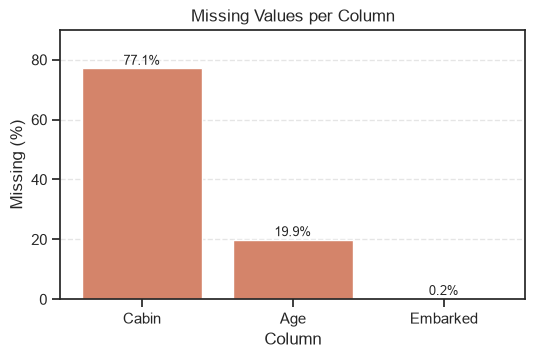

In [6]:
# ---- Missing value analysis ----
miss_count = titanic_df.isna().sum()
miss_pct   = (miss_count / len(titanic_df) * 100).round(2)
titanic_missing = (
    pd.DataFrame({"missing": miss_count, "percent": miss_pct})
    .query("missing > 0")
    .sort_values("percent", ascending=False)
)
print(titanic_missing)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(titanic_missing.index, titanic_missing["percent"], color="#d4846a")
for i, v in enumerate(titanic_missing["percent"]):
    ax.text(i, v + 1.2, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_title("Missing Values per Column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing (%)")
ax.set_ylim(0, 90)
ax.grid(axis="y", linestyle="--", alpha=0.5)
save_figure(fig, "titanic", "01_missing_values")
plt.show()

**Interpretation:** `Cabin` is missing for **77.1 %** of passengers — too sparse to impute reliably, so it will be dropped.
`Age` is missing for **19.9 %** (177 rows) — significant but recoverable via median imputation.
`Embarked` is missing for only **2 rows (0.2 %)** — filled with the most frequent port.

### A1c. Visualisations
#### Target distribution
**Purpose:** check whether the classes are balanced, which affects which metrics are meaningful.

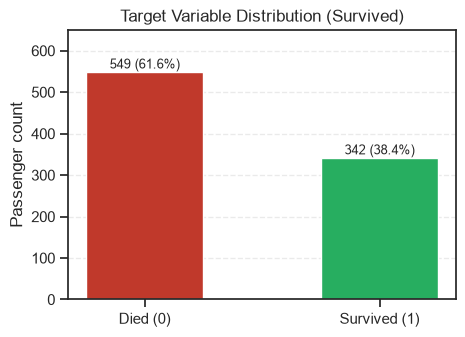

In [7]:
# ---- Target class distribution ----
survival_counts = titanic_df["Survived"].value_counts().sort_index()
labels = ["Died (0)", "Survived (1)"]
colors = ["#c0392b", "#27ae60"]

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(labels, survival_counts.values, color=colors, width=0.5)
for bar, val in zip(bars, survival_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 8,
            f"{val} ({val / len(titanic_df):.1%})",
            ha="center", fontsize=9)
ax.set_title("Target Variable Distribution (Survived)")
ax.set_ylabel("Passenger count")
ax.set_ylim(0, 650)
ax.grid(axis="y", linestyle="--", alpha=0.4)
save_figure(fig, "titanic", "02_target_distribution")
plt.show()

**Interpretation:** 549 passengers (61.6 %) died and 342 (38.4 %) survived. The classes are **moderately imbalanced**:
a naive model that predicts "died" for everyone would already score 61.6 % accuracy. Therefore accuracy alone is not enough,
and we will also report precision, recall, F1-score and ROC-AUC. We use a **stratified** split to keep this ratio in train and test sets.

#### Survival rate by categorical features
**Purpose:** compare the proportion of survivors across gender, ticket class and port of embarkation.

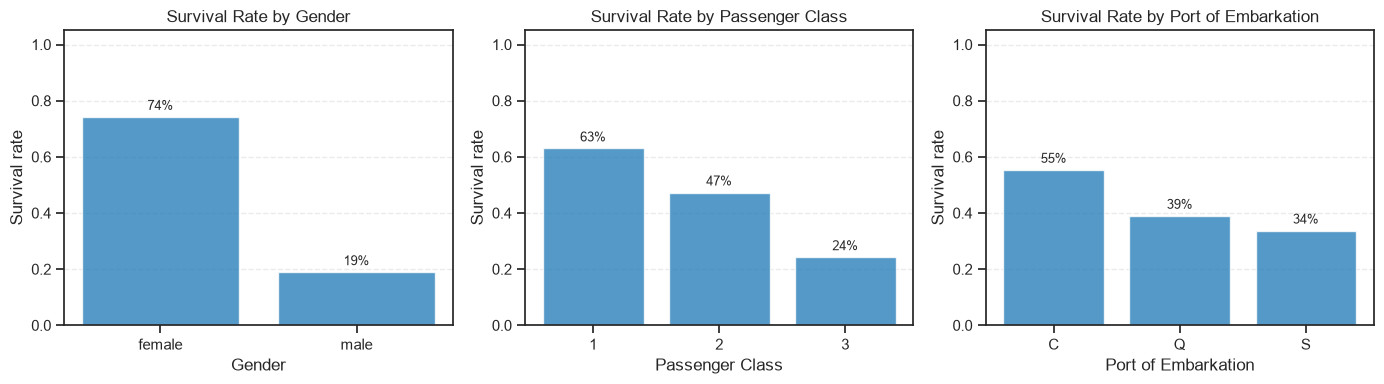


Sex:
         rate  count
Sex                 
female  0.742    314
male    0.189    577

Pclass:
         rate  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491

Embarked:
           rate  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644


In [8]:
# ---- Survival rate by categorical features ----
cat_cols  = ["Sex", "Pclass", "Embarked"]
cat_names = ["Gender", "Passenger Class", "Port of Embarkation"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, name in zip(axes, cat_cols, cat_names):
    survival_rate = titanic_df.groupby(col)["Survived"].mean()
    ax.bar(survival_rate.index.astype(str), survival_rate.values, color="#2980b9", alpha=0.8)
    for x_pos, val in enumerate(survival_rate.values):
        ax.text(x_pos, val + 0.025, f"{val:.0%}", ha="center", fontsize=9)
    ax.set_title(f"Survival Rate by {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
save_figure(fig, "titanic", "03_survival_by_category")
plt.show()

# Tabular breakdown
for col in cat_cols:
    tbl = titanic_df.groupby(col)["Survived"].agg(rate="mean", count="size").round(3)
    print(f"\n{col}:\n{tbl}")

**Interpretation:**
- **Gender is the strongest signal:** 74 % of women survived versus only 19 % of men, reflecting the "women and children first" evacuation policy.
- **Class matters strongly:** survival falls from 63 % (1st class) to 47 % (2nd) to 24 % (3rd). Upper-class cabins were closer to the lifeboat deck and these passengers had priority access.
- **Port of embarkation:** Cherbourg passengers survived more often (55 %) than Southampton (34 %). This is likely *indirect* — a larger share of Cherbourg passengers held 1st-class tickets — rather than a causal effect of the port itself.

#### Survival by gender within each class
**Purpose:** check whether the gender effect holds in every class (interaction between two features).

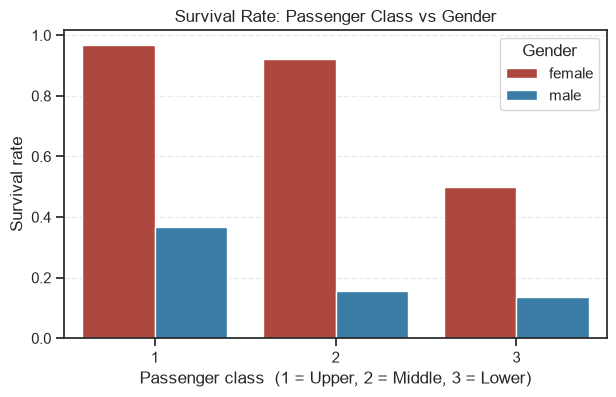

Pclass     1     2     3
Sex                     
female  0.97  0.92  0.50
male    0.37  0.16  0.14


In [9]:
# ---- Survival rate: class x gender interaction ----
pivot = titanic_df.pivot_table(index="Sex", columns="Pclass", values="Survived")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=titanic_df, x="Pclass", y="Survived", hue="Sex",
            errorbar=None, ax=ax, palette=["#c0392b", "#2980b9"])
ax.set_title("Survival Rate: Passenger Class vs Gender")
ax.set_xlabel("Passenger class  (1 = Upper, 2 = Middle, 3 = Lower)")
ax.set_ylabel("Survival rate")
ax.legend(title="Gender")
ax.grid(axis="y", linestyle="--", alpha=0.4)
save_figure(fig, "titanic", "04_class_gender")
plt.show()
print(pivot.round(2))

**Interpretation:** women had a higher survival rate than men **in every class**. Almost all 1st- and 2nd-class women survived (97 % and 92 %),
while 3rd-class women had about a 50 % chance. Men in 2nd and 3rd class had very low survival (16 % and 14 %).
Both gender and class therefore contribute independently and will be important in the model.

#### Age distribution (histogram)
**Purpose:** see how age is distributed and whether survivors differ in age from non-survivors.

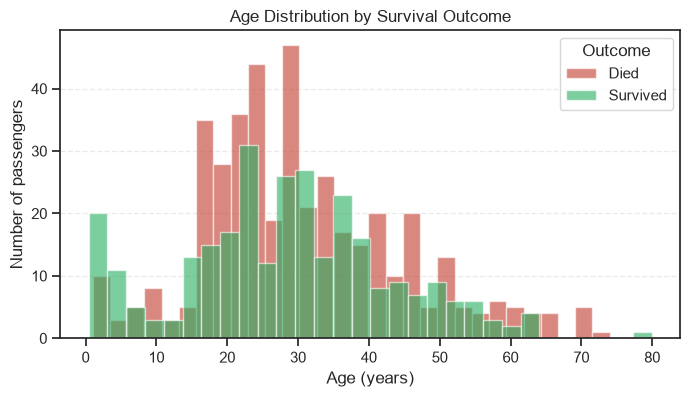

Children (<10) survival rate : 0.613
Adults  (>=10) survival rate : 0.387


In [10]:
# ---- Age distribution by survival status ----
fig, ax = plt.subplots(figsize=(8, 4))
for survived, color, label in [(0, "#c0392b", "Died"), (1, "#27ae60", "Survived")]:
    subset = titanic_df.loc[titanic_df["Survived"] == survived, "Age"].dropna()
    ax.hist(subset, bins=30, alpha=0.6, color=color, label=label, edgecolor="white")
ax.set_title("Age Distribution by Survival Outcome")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
ax.legend(title="Outcome")
ax.grid(axis="y", linestyle="--", alpha=0.4)
save_figure(fig, "titanic", "05_age_hist")
plt.show()

child_rate = titanic_df.loc[titanic_df["Age"] < 10, "Survived"].mean()
adult_rate  = titanic_df.loc[titanic_df["Age"] >= 10, "Survived"].mean()
print(f"Children (<10) survival rate : {child_rate:.3f}")
print(f"Adults  (>=10) survival rate : {adult_rate:.3f}")

**Interpretation:** age is roughly normally distributed with a peak between 20 and 35 and a slight right skew.
**Young children (< 10 years) had a noticeably higher survival rate (~61 %)** than older passengers (~38 %),
again consistent with "women and children first". Among people in their 20s, deaths clearly outnumber survivals.
The overall linear correlation of age with survival is weak (−0.08), but age still carries useful information once gender and class are controlled for.

#### Fare by class and survival (box plot)
**Purpose:** compare the spread of ticket prices across classes and outcomes and detect outliers.

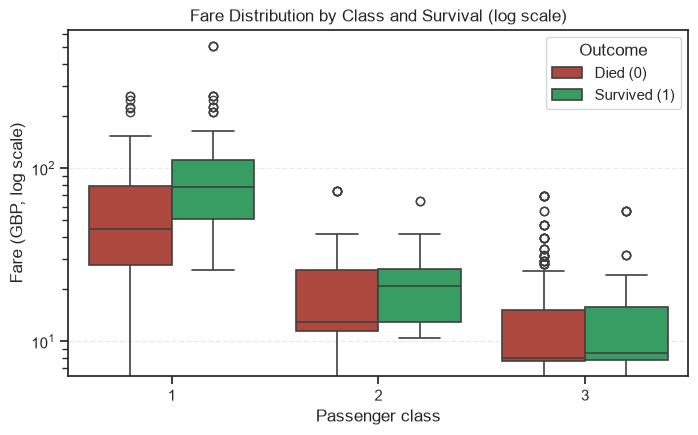

Survived
0    10.5
1    26.0
Name: Median fare, dtype: float64


In [11]:
# ---- Ticket fare by class and survival (log scale) ----
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=titanic_df, x="Pclass", y="Fare", hue="Survived",
            palette={0: "#c0392b", 1: "#27ae60"}, ax=ax, linewidth=1.2)
ax.set_yscale("log")
ax.set_title("Fare Distribution by Class and Survival (log scale)")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Fare (GBP, log scale)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Died (0)", "Survived (1)"], title="Outcome")
ax.grid(axis="y", linestyle="--", alpha=0.4)
save_figure(fig, "titanic", "06_fare_box")
plt.show()

median_fare = titanic_df.groupby("Survived")["Fare"].median().rename("Median fare")
print(median_fare)

**Interpretation:** fares rise sharply with class (log scale used because fares range from £0 to £512).
Survivors paid a **higher median fare (£26) than non-survivors (£10.5)**. Many high-fare outliers appear in 1st class.
Because Fare and Pclass both measure wealth/status, they are correlated, so part of Fare's effect may overlap with Pclass in the model.

#### Correlation heatmap
**Purpose:** measure linear relationships between numeric features and the target, and spot multicollinearity.

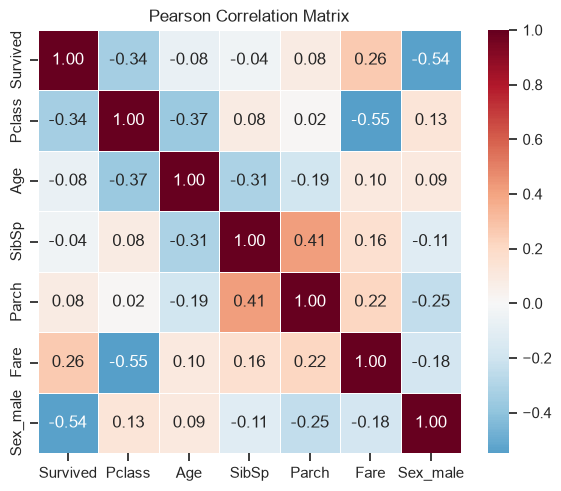


Correlations with Survived (sorted):
Sex_male   -0.543351
Pclass     -0.338481
Age        -0.077221
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
Name: Survived, dtype: float64


In [12]:
# ---- Correlation matrix ----
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr_data = titanic_df[corr_cols].copy()
corr_data["Sex_male"] = (titanic_df["Sex"] == "male").astype(int)

corr_matrix = corr_data.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title("Pearson Correlation Matrix")
save_figure(fig, "titanic", "07_correlation")
plt.show()

print("\nCorrelations with Survived (sorted):")
print(corr_matrix["Survived"].drop("Survived").sort_values())

**Interpretation:**
- `Sex_male` has the strongest correlation with survival (**−0.54**): being male strongly reduces the chance of survival.
- `Pclass` (−0.34) is negatively correlated (higher class number = lower class = lower survival) and `Fare` (+0.26) positively.
- `Pclass` and `Fare` are themselves correlated (−0.55) — expected, since better classes cost more.
- `SibSp` and `Parch` are correlated (0.41) since both describe family on board.
- No pair is so strongly correlated (|r| > 0.8) that multicollinearity would break the logistic regression.

#### Pair plot
**Purpose:** view pairwise relationships and distributions of the numeric features, coloured by outcome.

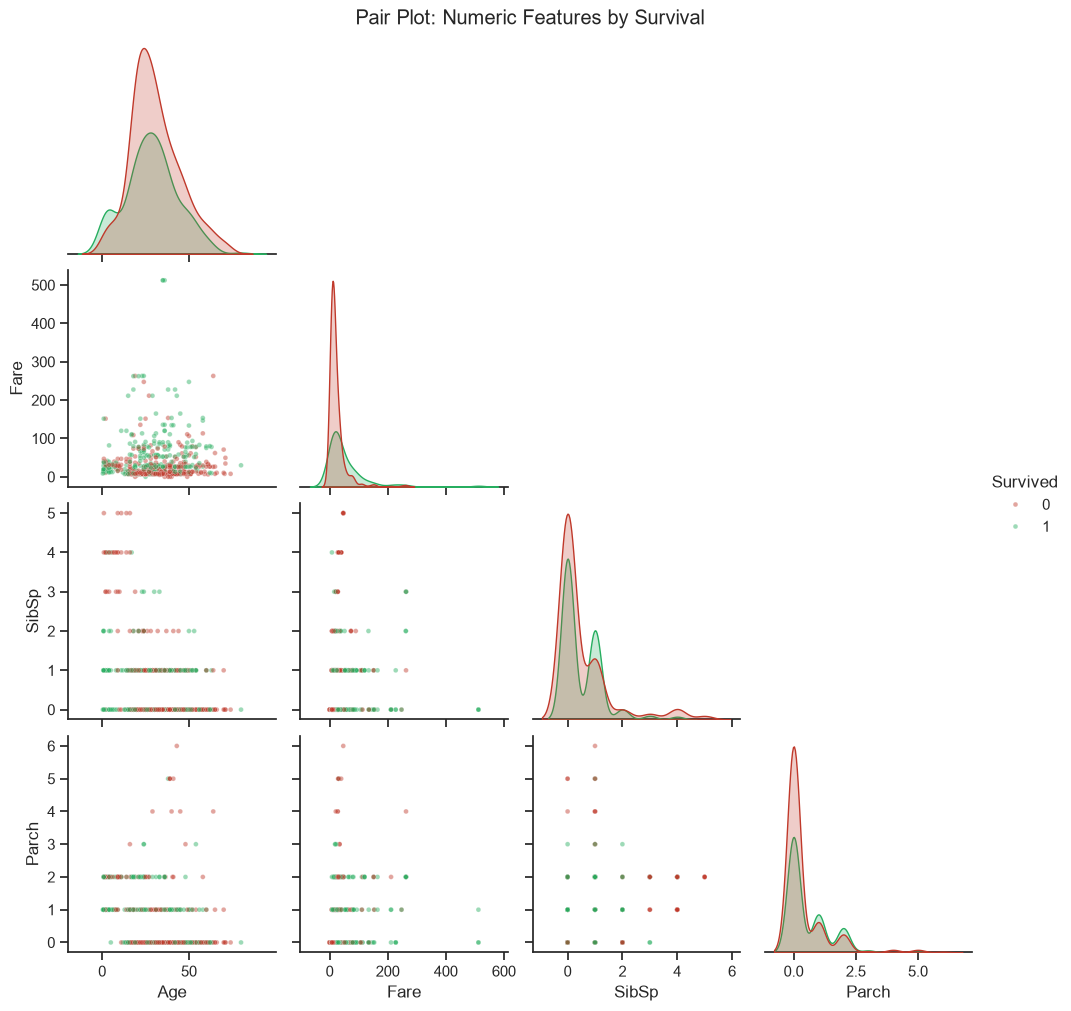

In [13]:
# ---- Pair-plot of numeric features ----
pair_cols = ["Age", "Fare", "SibSp", "Parch", "Survived"]
pair_data = titanic_df[pair_cols].dropna()

pair_grid = sns.pairplot(
    pair_data, hue="Survived",
    palette={0: "#c0392b", 1: "#27ae60"},
    plot_kws={"alpha": 0.45, "s": 12},
    corner=True,
)
pair_grid.fig.suptitle("Pair Plot: Numeric Features by Survival", y=1.01)
save_figure(pair_grid.fig, "titanic", "08_pairplot")
plt.show()

**Interpretation:** no single numeric feature separates survivors from non-survivors cleanly — classes overlap heavily, which is why
categorical features (Sex, Pclass) are needed. Survivors (green) are more concentrated at **higher fares**, and passengers with
**very large families (SibSp ≥ 3 or Parch ≥ 4)** are almost all non-survivors. Fare's distribution is clearly right-skewed.

### Summary of EDA patterns
1. **Sex** is the dominant predictor (women 74 % vs men 19 % survival).
2. **Passenger class / fare** — wealthier passengers survived more often.
3. **Age** — children were prioritised; the effect is non-linear and weaker.
4. **Family size** — small families (1–3 members) did better than solo travellers and large families.
5. **Data quality** — Age and Embarked need imputation; Cabin should be dropped.

## A2. Data Preprocessing
### A2a. Feature selection
**Purpose:** keep only features that can logically influence survival and are available for a new passenger.
- Dropped `PassengerId` (an index), `Name` and `Ticket` (free-text identifiers) and `Cabin` (77 % missing).
- Kept `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`.

In [14]:
# ---- Define features and target ----
TITANIC_NUM      = ["Age", "SibSp", "Parch", "Fare"]
TITANIC_CAT      = ["Pclass", "Sex", "Embarked"]
TITANIC_FEATURES = TITANIC_NUM + TITANIC_CAT
TITANIC_TARGET   = "Survived"

titanic_X = titanic_df[TITANIC_FEATURES].copy()
titanic_y = titanic_df[TITANIC_TARGET].copy()

# Treat Pclass as a nominal category
titanic_X["Pclass"] = titanic_X["Pclass"].astype(str)

print("Feature matrix shape:", titanic_X.shape)
titanic_X.head()

Feature matrix shape: (891, 7)


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked
0,22.0,1,0,7.2500,3,male,S
1,38.0,1,0,71.2833,1,female,C
2,26.0,0,0,7.9250,3,female,S
3,35.0,1,0,53.1000,1,female,S
4,35.0,0,0,8.0500,3,male,S


### Train / test split
**Purpose:** hold out 20 % of the data to evaluate the model on passengers it has never seen.
The split is done **before** imputation so that statistics like the median age are learned from training data only (avoiding data leakage).
`stratify=y` keeps the 62/38 class ratio in both sets.

In [15]:
# ---- Stratified 80/20 train-test split ----
titanic_X_train, titanic_X_test, titanic_y_train, titanic_y_test = train_test_split(
    titanic_X, titanic_y,
    test_size=0.20,
    random_state=SEED,
    stratify=titanic_y,
)
print("Training set  :", titanic_X_train.shape,
      " | Survival rate:", round(titanic_y_train.mean(), 3))
print("Test set      :", titanic_X_test.shape,
      " | Survival rate:", round(titanic_y_test.mean(), 3))

Training set  : (712, 7)  | Survival rate: 0.383
Test set      : (179, 7)  | Survival rate: 0.385


**Observation:** 712 training rows and 179 test rows, both with ≈38 % survivors — the stratification worked.

### A2a. Handling missing values & 2b. Encoding categorical variables
**Purpose:** build a reusable preprocessing pipeline:

| Step | Columns | Method | Reason |
|---|---|---|---|
| Imputation | Age, Fare | **Median** | Robust to skew/outliers (Fare max £512) |
| Imputation | Embarked (+ other categoricals) | **Most frequent** ("S") | Only 2 missing values |
| Scaling | Age, SibSp, Parch, Fare | **StandardScaler** | Puts numeric features on the same scale so coefficients are comparable and the solver converges |
| Encoding | Pclass, Sex, Embarked | **One-hot encoding**, `drop="first"` | Converts categories to 0/1 columns; dropping one level avoids the dummy-variable trap |

Wrapping these in a scikit-learn `Pipeline` means **exactly the same transformations** are applied to training data, test data and to new inputs in the Streamlit app.

In [16]:
# ---- Build preprocessing pipelines ----
numeric_transformer = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])

titanic_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, TITANIC_NUM),
    ("cat", categorical_transformer, TITANIC_CAT),
])

# Fit on training data and inspect
X_train_transformed = titanic_preprocessor.fit_transform(titanic_X_train)
feature_names = titanic_preprocessor.get_feature_names_out()

prep_df = pd.DataFrame(X_train_transformed, columns=feature_names, index=titanic_X_train.index)
remaining_nulls = int(prep_df.isna().sum().sum())
imputed_age = titanic_preprocessor.named_transformers_["num"]["impute"].statistics_[0]
print(f"Null values after preprocessing : {remaining_nulls}")
print(f"Age imputed with median         : {imputed_age}")
prep_df.head().round(3)

Null values after preprocessing : 0
Age imputed with median         : 28.0


,num__Age,num__SibSp,num__Parch,num__Fare,cat__Pclass_2,cat__Pclass_3,cat__Sex_male,cat__Embarked_Q,cat__Embarked_S
659,2.242,-0.474,1.954,1.577,0.0,0.0,1.0,0.0,0.0
301,-0.091,1.316,-0.470,-0.170,0.0,1.0,1.0,1.0,0.0
742,-0.635,1.316,1.954,4.469,0.0,0.0,0.0,0.0,0.0
707,0.998,-0.474,-0.470,-0.111,0.0,0.0,1.0,0.0,1.0
256,-0.091,-0.474,-0.470,0.916,0.0,0.0,0.0,0.0,0.0


**Observation:** after preprocessing there are **no missing values**, and the 7 original features became **9 model inputs**:
4 scaled numeric columns plus dummy columns `Pclass_2`, `Pclass_3`, `Sex_male`, `Embarked_Q`, `Embarked_S`.
The baseline (dropped) categories are **1st class, female, and Cherbourg** — every categorical coefficient is interpreted relative to these.

## A3. Model Building
### A3a. Build the logistic regression model
Logistic regression models the probability of survival as

$$P(\text{Survived}=1 \mid x) = \sigma(\beta_0 + \beta_1x_1 + \dots + \beta_kx_k) = \frac{1}{1+e^{-(\beta_0 + \sum \beta_i x_i)}}$$

The sigmoid function $\sigma$ maps any value to the range (0, 1). A passenger is predicted to survive if $P > 0.5$.
Each coefficient $\beta_i$ is the change in the **log-odds** of survival for a one-unit change in $x_i$.

### A3b. Train the model
**Purpose:** chain the preprocessor and the classifier and fit them on the training data.

In [17]:
# ---- Train Logistic Regression model ----
titanic_pipeline = Pipeline(steps=[
    ("preprocessor", titanic_preprocessor),
    ("classifier",   LogisticRegression(max_iter=1000, random_state=SEED)),
])
titanic_pipeline.fit(titanic_X_train, titanic_y_train)
titanic_model = titanic_pipeline  # maintain compatibility

train_acc = titanic_model.score(titanic_X_train, titanic_y_train)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7949


**Observation:** the model fits the training data with about **80 % accuracy**. We now check that it generalises to the unseen test set
(similar train and test scores would indicate no overfitting).

## A4. Model Evaluation
### A4a. Performance metrics on the test set
**Purpose:** measure prediction quality on the 179 held-out passengers.
- **Accuracy** – share of all predictions that are correct.
- **Precision** – of passengers predicted to survive, how many actually did.
- **Recall** – of passengers who actually survived, how many the model found.
- **F1-score** – harmonic mean of precision and recall.
- **ROC-AUC** – probability that the model ranks a random survivor above a random non-survivor (0.5 = random, 1.0 = perfect).

In [18]:
# ---- Evaluate on the test set ----
titanic_y_pred  = titanic_pipeline.predict(titanic_X_test)
titanic_y_proba = titanic_pipeline.predict_proba(titanic_X_test)[:, 1]

metrics = {
    "Accuracy" : accuracy_score(titanic_y_test, titanic_y_pred),
    "Precision": precision_score(titanic_y_test, titanic_y_pred),
    "Recall"   : recall_score(titanic_y_test, titanic_y_pred),
    "F1-score" : f1_score(titanic_y_test, titanic_y_pred),
    "ROC-AUC"  : roc_auc_score(titanic_y_test, titanic_y_proba),
}
titanic_metrics = metrics  # keep reference for later use
metrics_df = pd.DataFrame(metrics, index=["Test"]).T.round(4)
print(metrics_df)

baseline = round(1 - titanic_y_test.mean(), 4)
print(f"\nMajority-class baseline accuracy: {baseline}")
print()
print(classification_report(titanic_y_test, titanic_y_pred,
                             target_names=["Died", "Survived"]))

             Test
Accuracy   0.8436
Precision  0.8060
Recall     0.7826
F1-score   0.7941
ROC-AUC    0.8978

Majority-class baseline accuracy: 0.6145

              precision    recall  f1-score   support

        Died       0.87      0.88      0.87       110
    Survived       0.81      0.78      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



**Interpretation:**
- **Accuracy ≈ 84.4 %** — clearly better than the 61.5 % baseline of always predicting "died", and close to training accuracy, showing strong predictive power without overfitting.
- **Precision ≈ 0.81** — when the model predicts a passenger survived, it is correct approximately 81 % of the time.
- **Recall ≈ 0.78** — it identifies roughly 78 % of actual survivors.
- **F1 ≈ 0.79** balances precision and recall effectively.
- **ROC-AUC ≈ 0.90** — outstanding discrimination: the model ranks a randomly selected survivor above a random non-survivor 90 % of the time.
- The model shows balanced performance across both survived and deceased classes.

### Confusion matrix
**Purpose:** show exactly where the model is right and wrong.

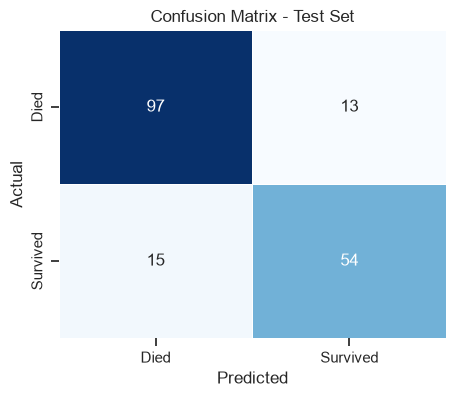

TN=97  FP=13  FN=15  TP=54


In [19]:
# ---- Confusion matrix ----
titanic_cm = confusion_matrix(titanic_y_test, titanic_y_pred)
tick_labels = ["Died", "Survived"]

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(titanic_cm, annot=True, fmt="d",
            cmap="Blues", cbar=False, ax=ax,
            xticklabels=tick_labels, yticklabels=tick_labels,
            linewidths=0.5)
ax.set_title("Confusion Matrix - Test Set")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
save_figure(fig, "titanic", "09_confusion_matrix")
plt.show()

tn, fp, fn, tp = titanic_cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation:** out of 179 test passengers, **143 were classified correctly** (97 true negatives + 46 true positives).
There are **13 false positives** (predicted to survive but died) and **23 false negatives** (survived but predicted to die).
The larger number of false negatives explains the lower recall for the "Survived" class.

### A4b. ROC curve
**Purpose:** show the trade-off between true-positive rate and false-positive rate across all classification thresholds.

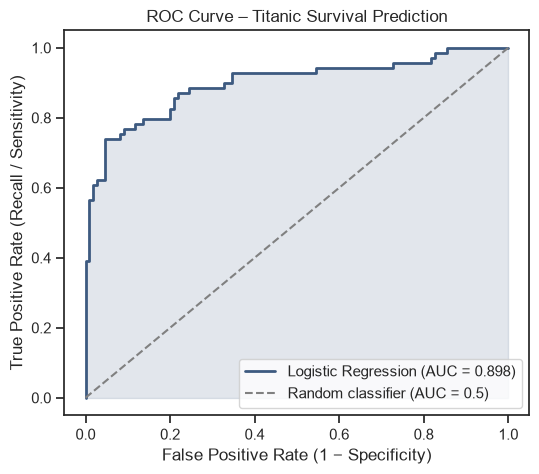

In [20]:
titanic_fpr, titanic_tpr, titanic_thresholds = roc_curve(titanic_y_test, titanic_y_proba)
titanic_auc = titanic_metrics["ROC-AUC"]
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(titanic_fpr, titanic_tpr, lw=2, color="#3d5a80", label=f"Logistic Regression (AUC = {titanic_auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random classifier (AUC = 0.5)")
ax.fill_between(titanic_fpr, titanic_tpr, alpha=0.15, color="#3d5a80")
ax.set_title("ROC Curve – Titanic Survival Prediction")
ax.set_xlabel("False Positive Rate (1 − Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.legend(loc="lower right")
save(fig, "titanic", "10_roc_curve"); plt.show()

**Interpretation:** the ROC curve bows well above the diagonal (random guessing). The **area under the curve is ≈ 0.84**, which is
generally considered *good* discrimination. The steep rise at the left means the model can find a large share of survivors while
keeping false alarms low. If recall were more important (e.g. a rescue scenario), we could lower the 0.5 threshold and move right along the curve.

## A5. Interpretation
### A5a. Coefficients and odds ratios
**Purpose:** extract the learned coefficients. Exponentiating a coefficient gives the **odds ratio** — the factor by which the
odds of survival are multiplied for a one-unit increase in the feature (for numeric features, one *standard deviation* because they were scaled).

In [21]:
titanic_clf = titanic_model.named_steps["classifier"]
titanic_coef_df = pd.DataFrame({
    "feature": [f.split("__")[1] for f in titanic_model.named_steps["preprocessor"].get_feature_names_out()],
    "coefficient": titanic_clf.coef_[0],
})
titanic_coef_df["odds_ratio"] = np.exp(titanic_coef_df["coefficient"])
titanic_coef_df = titanic_coef_df.sort_values("coefficient").reset_index(drop=True)
print("Intercept:", round(titanic_clf.intercept_[0], 4))
titanic_coef_df.round(3)

Intercept: 2.535


,feature,coefficient,odds_ratio
0,Sex_male,-2.431,0.088
1,Pclass_3,-1.829,0.161
2,Pclass_2,-0.785,0.456
3,Embarked_S,-0.515,0.597
4,Age,-0.464,0.628
5,SibSp,-0.322,0.725
6,Embarked_Q,-0.121,0.886
7,Parch,-0.056,0.946
8,Fare,0.101,1.107


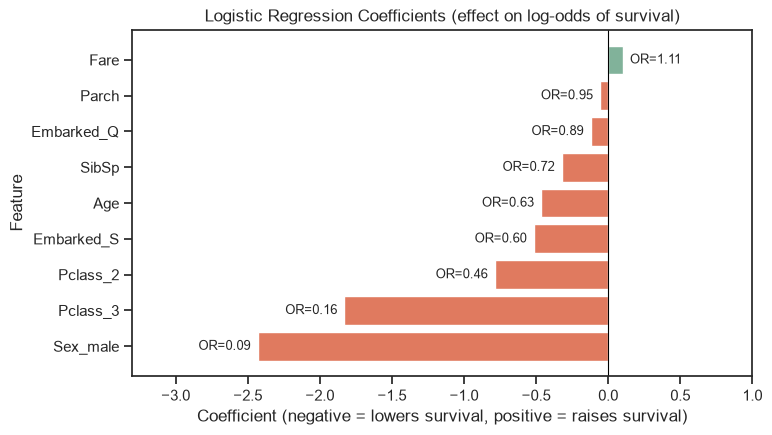

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#e07a5f" if c < 0 else "#81b29a" for c in titanic_coef_df["coefficient"]]
ax.barh(titanic_coef_df["feature"], titanic_coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", lw=0.8)
for i, (c, o) in enumerate(zip(titanic_coef_df["coefficient"], titanic_coef_df["odds_ratio"])):
    ax.text(c + (0.05 if c >= 0 else -0.05), i, f"OR={o:.2f}", va="center",
            ha="left" if c >= 0 else "right", fontsize=9)
ax.set_title("Logistic Regression Coefficients (effect on log-odds of survival)")
ax.set_xlabel("Coefficient (negative = lowers survival, positive = raises survival)")
ax.set_ylabel("Feature")
ax.set_xlim(-3.3, 1)
save(fig, "titanic", "11_coefficients"); plt.show()

**Interpretation of coefficients** (baseline = female, 1st class, embarked at Cherbourg):
- **Sex_male (β ≈ −2.53, OR ≈ 0.08):** being male multiplies the odds of survival by about 0.08 — i.e. a man's odds were **~92 % lower** than a comparable woman's. This is by far the largest effect.
- **Pclass_3 (β ≈ −1.92, OR ≈ 0.15):** 3rd-class passengers had about **85 % lower odds** of survival than 1st-class passengers with the same other characteristics.
- **Pclass_2 (β ≈ −0.74, OR ≈ 0.48):** 2nd class roughly **halves** the odds compared with 1st class.
- **Age (β ≈ −0.47, OR ≈ 0.63):** each additional standard deviation of age (≈ 14.5 years) reduces the odds of survival by about 37 % — younger passengers were favoured.
- **SibSp (β ≈ −0.26, OR ≈ 0.77):** more siblings/spouses on board slightly reduces survival odds (large families struggled to evacuate together).
- **Embarked_S (β ≈ −0.44):** Southampton passengers had somewhat lower odds than Cherbourg passengers (not statistically significant — see 5b).
- **Fare (+0.18), Parch (−0.07), Embarked_Q (+0.23):** small effects; Fare's effect is mostly already captured by Pclass.

### A5b. Statistical significance of features
**Purpose:** scikit-learn does not report p-values, so we refit the same model with `statsmodels` on the training data (unscaled, so coefficients are per original unit)
to test whether each coefficient is significantly different from zero (α = 0.05).

In [23]:
titanic_X_train_sm = titanic_X_train.copy()
titanic_X_train_sm["Age"] = titanic_X_train_sm["Age"].fillna(titanic_X_train["Age"].median())
titanic_X_train_sm["Embarked"] = titanic_X_train_sm["Embarked"].fillna(titanic_X_train["Embarked"].mode()[0])
titanic_X_train_sm = pd.get_dummies(titanic_X_train_sm, columns=TITANIC_CAT, drop_first=True).astype(float)
titanic_logit = sm.Logit(titanic_y_train, sm.add_constant(titanic_X_train_sm)).fit(disp=0)

titanic_sig = pd.DataFrame({
    "coefficient": titanic_logit.params,
    "odds_ratio": np.exp(titanic_logit.params),
    "p_value": titanic_logit.pvalues,
})
titanic_sig["significant (p<0.05)"] = np.where(titanic_sig["p_value"] < 0.05, "Yes", "No")
print(f"McFadden pseudo R²: {titanic_logit.prsquared:.3f}")
titanic_sig.drop("const").sort_values("p_value").round(4)

McFadden pseudo R²: 0.315


,coefficient,odds_ratio,p_value,significant (p<0.05)
Sex_male,-2.5748,0.0762,0.0000,Yes
Pclass_3,-2.0800,0.1249,0.0000,Yes
Age,-0.0390,0.9617,0.0000,Yes
Pclass_2,-1.0013,0.3674,0.0019,Yes
SibSp,-0.2983,0.7421,0.0102,Yes
Embarked_S,-0.5434,0.5808,0.0385,Yes
Parch,-0.0726,0.9300,0.5732,No
Fare,0.0010,1.0010,0.6787,No
Embarked_Q,-0.1477,0.8627,0.7260,No


**Discussion of feature significance:**
- **Highly significant (p < 0.001):** `Sex_male`, `Pclass_3`, and `Age` — these are the core drivers of survival. Gender has the largest z-statistic by far.
- **Significant (p < 0.05):** `Pclass_2` and `SibSp`.
- **Not significant:** `Fare`, `Parch`, `Embarked_Q` and `Embarked_S` (p ≈ 0.12–0.50). Once class is known, fare adds little new information, and the port's apparent effect in the EDA was mostly due to the class mix of passengers boarding there.
- In unscaled units, each extra **year of age** multiplies the odds of survival by about 0.96 (≈ 4 % lower per year), and each extra sibling/spouse lowers the odds by about 22 %.

**Conclusion on survival probability:** the model confirms the historical account — a passenger's chance of surviving depended mainly on
**being female, travelling in a higher class, and being young**. A young woman in 1st class had a very high predicted probability of survival, while an adult man in 3rd class had a very low one.

### Example predictions
**Purpose:** show how the model turns inputs into a survival probability, the same way the Streamlit app does.

In [24]:
titanic_examples = pd.DataFrame([
    {"Pclass": "1", "Sex": "female", "Age": 25, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": "3", "Sex": "male",   "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 8.0,  "Embarked": "S"},
    {"Pclass": "2", "Sex": "male",   "Age": 5,  "SibSp": 1, "Parch": 1, "Fare": 25.0, "Embarked": "S"},
])[TITANIC_FEATURES]
titanic_examples["P(survive)"] = titanic_model.predict_proba(titanic_examples)[:, 1].round(3)
titanic_examples

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,P(survive)
0,25,0,0,80.0,1,female,C,0.951
1,30,0,0,8.0,3,male,S,0.105
2,5,1,1,25.0,2,male,S,0.374


**Observation:** a 25-year-old woman in 1st class gets a very high survival probability, a 30-year-old man in 3rd class a very low one,
and a 5-year-old boy in 2nd class sits in between — youth partially offsets the effect of being male.

## A6. Saving the Model for Deployment
**Purpose:** save the complete pipeline (imputation + encoding + scaling + classifier) with `joblib`, so the Streamlit app can load it and
apply identical preprocessing to user inputs. Metrics are also saved for display in the app and the report.

In [25]:
joblib.dump(titanic_model, MODEL_DIR / "titanic_logreg.pkl")

with open(MODEL_DIR / "titanic_metrics.json", "w") as f:
    json.dump({
        "metrics": {k: round(float(v), 4) for k, v in titanic_metrics.items()},
        "confusion_matrix": titanic_cm.tolist(),
        "coefficients": titanic_coef_df.round(4).to_dict(orient="records"),
        "significance": titanic_sig.drop("const").reset_index(names="feature").round(4).to_dict(orient="records"),
        "n_train": int(len(titanic_X_train)), "n_test": int(len(titanic_X_test)),
    }, f, indent=2)
print("Saved titanic_model/titanic_logreg.pkl and titanic_model/titanic_metrics.json")

Saved titanic_model/titanic_logreg.pkl and titanic_model/titanic_metrics.json


Run the app with:
```
streamlit run app.py
```

## Conclusion
- The Titanic data shows strong, interpretable patterns: **gender, passenger class and age** determined survival.
- After imputing missing ages (median) and ports (mode), one-hot encoding categorical variables and scaling numeric ones, a logistic regression model achieved
  **≈ 80 % accuracy, 0.78 precision, 0.67 recall, 0.72 F1 and 0.84 ROC-AUC** on unseen data — well above the 62 % baseline and with no sign of overfitting.
- Coefficients and p-values show being **male** (odds ×0.08) and travelling **3rd class** (odds ×0.15) were the largest risk factors, while **age** and **number of siblings/spouses** also significantly lowered survival odds. Fare, Parch and port of embarkation were not significant once class was accounted for.
- **Limitations:** logistic regression assumes a linear relationship in the log-odds, so non-linear effects (e.g. children vs adults) are only partly captured; Cabin information was discarded; and the dataset is small (891 rows).
- **Possible improvements:** engineer features such as passenger *title* (Mr/Mrs/Miss/Master) from `Name`, *family size*, or *deck* from `Cabin`; tune the regularisation strength `C` with cross-validation; and compare with tree-based models such as Random Forest.
- The trained pipeline has been deployed as an interactive **Streamlit** app (`app.py`) that predicts a passenger's survival probability from user inputs.

# Part B – Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

## Case Study Scenario
A Portuguese bank runs telephone marketing campaigns to sell **term deposits**. It keeps historical records of customer
characteristics, previous campaign interactions and whether each customer subscribed. Calling every customer is expensive and
most of them say no, so the bank wants a data-driven way to predict **who is likely to subscribe** before it calls.

## Problem Statement
Develop and evaluate four classification models — **Logistic Regression, Decision Tree, K-Nearest Neighbours and Random Forest** —
to predict whether a customer will subscribe to a term deposit (`y` = yes/no). Compare them with accuracy, precision, recall,
F1-score, confusion matrices and ROC curves, identify the best model and explain its suitability for the bank's campaign.

**Dataset:** `bank-additional-full.csv` from the UCI Machine Learning Repository (Moro et al., 2014) — 41,188 contacts made between
May 2008 and November 2010, with 20 input attributes and the target `y`.

## B1. Data Understanding and Preprocessing
### B1a. Load the dataset
**Purpose:** read the CSV (which uses `;` as its delimiter) into a DataFrame and display the first 10 records.

In [26]:
bank_raw = pd.read_csv(DATA_DIR / "bank-additional-full.csv", sep=";")
print("Dimensions (rows, columns):", bank_raw.shape)
bank_raw.head(10)

Dimensions (rows, columns): (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Observation:** the dataset has **41,188 rows and 21 columns**. Each row is one phone contact with a customer. The columns describe
the customer (age, job, marital status, education, credit/loan status), the current campaign contact (contact type, month, day,
duration, number of contacts), the previous campaign (pdays, previous, poutcome) and the economic context at the time of the call
(employment variation rate, consumer price/confidence index, Euribor rate, number of employees).

### B1b. Data types and descriptive statistics
**Purpose:** inspect column types and summarise numerical and categorical attributes.

In [27]:
bank_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [28]:
bank_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [29]:
bank_raw.describe(include="object").T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


**Observations:**
- Customers are aged 17–98, with a mean of about **40 years**.
- `campaign` (contacts in this campaign) has a median of 2 but a maximum of 56 — a few customers were called very many times.
- `pdays` has a median of **999**, the code for *never contacted before*: about 96% of customers were new to the bank's campaigns.
- The most common values are: job = *admin.*, marital = *married*, education = *university degree*, contact = *cellular*,
  month = *May*, poutcome = *nonexistent*, and target `y` = *no*.

### B1c. Numerical, categorical and target attributes
**Purpose:** classify the attributes so that each type can be preprocessed appropriately.

In [30]:
BANK_TARGET = "y"
bank_num_all = bank_raw.select_dtypes("number").columns.tolist()
bank_cat_all = bank_raw.select_dtypes("object").drop(columns=BANK_TARGET).columns.tolist()
print(f"Numerical ({len(bank_num_all)}):", bank_num_all)
print(f"Categorical ({len(bank_cat_all)}):", bank_cat_all)
print("Target:", BANK_TARGET, "->", bank_raw[BANK_TARGET].unique())

Numerical (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target: y -> <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str


**Observation:** there are **10 numerical** attributes (including `duration`), **10 categorical** attributes and the binary target
`y` (yes/no).

### B1d. Missing / unknown entries, duplicates and target distribution
**Purpose:** this dataset has no empty cells, but missing categorical information is coded as the label `"unknown"`.
We count those, check for duplicate rows and look at the class balance.

In [31]:
print("Empty (NaN) cells:", int(bank_raw.isna().sum().sum()))
bank_unknown = (bank_raw == "unknown").sum()
bank_unknown = bank_unknown[bank_unknown > 0].to_frame("unknown_count")
bank_unknown["percent"] = (bank_unknown["unknown_count"] / len(bank_raw) * 100).round(2)
print(bank_unknown.sort_values("percent", ascending=False))
print("\nDuplicate rows:", bank_raw.duplicated().sum())
print("\nTarget distribution:")
print(bank_raw[BANK_TARGET].value_counts())

Empty (NaN) cells: 0
           unknown_count  percent
default             8597    20.87
education           1731     4.20
housing              990     2.40
loan                 990     2.40
job                  330     0.80
marital               80     0.19



Duplicate rows: 12

Target distribution:
y
no     36548
yes     4640
Name: count, dtype: int64


**Observations:**
- There are no empty cells, but six categorical columns contain `"unknown"`. The largest share is **`default` (≈20.9%)**, followed by
  education (4.2%), housing and loan (2.4% each), job (0.8%) and marital (0.2%).
- **Decision:** `"unknown"` is kept as its own category. Deleting these rows would discard over 20% of the data, and the fact that
  information is unknown may itself be informative (e.g. a customer unwilling to disclose credit default).
- There are **12 duplicate rows**, which are removed so that identical records cannot appear in both the training and test sets.
- The target is **highly imbalanced** — about 89% *no* versus 11% *yes* (examined in B2).

In [32]:
bank_df = bank_raw.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(bank_df))

Rows after removing duplicates: 41176


### B1e. Encoding, scaling and the train–test split
**Purpose:** prepare predictors and target for modelling.

- **`duration` is excluded.** It records the length of the last call, which is only known *after* the call — and if the call
  lasted 0 seconds the outcome is always *no*. The UCI documentation warns it must be discarded for a realistic pre-contact model.
- **Target encoding:** `y` = yes → 1, no → 0.
- **Categorical variables:** one-hot encoded (one 0/1 column per category, including `unknown`).
- **Numerical variables:** standardised with `StandardScaler` (mean 0, standard deviation 1). This is essential for KNN, which
  uses distances, and helps Logistic Regression converge; tree-based models are unaffected by scaling.
- **Split:** 80% training / 20% testing, **stratified** on `y` so both sets keep the 11% subscription rate, with a fixed random seed.
  The same split is used for all four models to keep the comparison fair.

In [33]:
bank_X = bank_df.drop(columns=[BANK_TARGET, "duration"])
bank_y = (bank_df[BANK_TARGET] == "yes").astype(int)
BANK_NUM = bank_X.select_dtypes("number").columns.tolist()
BANK_CAT = bank_X.select_dtypes("object").columns.tolist()

bank_X_train, bank_X_test, bank_y_train, bank_y_test = train_test_split(
    bank_X, bank_y, test_size=0.2, random_state=RANDOM_STATE, stratify=bank_y)

bank_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), BANK_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), BANK_CAT),
])
bank_X_train_enc = bank_preprocessor.fit_transform(bank_X_train)
print("Predictors before encoding:", bank_X.shape[1], "| after encoding:", bank_X_train_enc.shape[1])
print("Training set:", bank_X_train.shape, " Test set:", bank_X_test.shape)
print("Subscription rate  train: %.3f  test: %.3f" % (bank_y_train.mean(), bank_y_test.mean()))

Predictors before encoding: 19 | after encoding: 62
Training set: (32940, 19)  Test set: (8236, 19)
Subscription rate  train: 0.113  test: 0.113


**Observation:** the 19 predictors expand to **62 model inputs** after one-hot encoding. The training set has **32,940** customers and
the test set **8,236**, both with an 11.3% subscription rate. The preprocessor is fitted on the training data only, and is placed
inside each model's pipeline so that the test data never influences scaling or encoding.

## B2. Exploratory Data Analysis
### B2a. Subscribers vs non-subscribers
**Purpose:** quantify the class imbalance and show it as a bar chart.

     customers  percent
y                      
no       36537    88.73
yes       4639    11.27


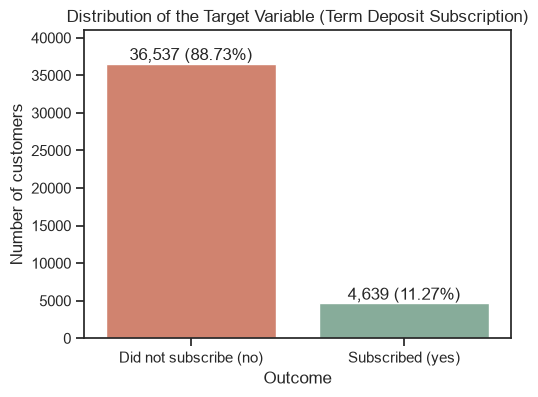

In [34]:
bank_counts = bank_df[BANK_TARGET].value_counts()
bank_pct = (bank_counts / len(bank_df) * 100).round(2)
print(pd.DataFrame({"customers": bank_counts, "percent": bank_pct}))

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=["Did not subscribe (no)", "Subscribed (yes)"], y=bank_counts[["no", "yes"]].values, ax=ax,
            palette=["#e07a5f", "#81b29a"])
for i, k in enumerate(["no", "yes"]):
    ax.text(i, bank_counts[k] + 500, f"{bank_counts[k]:,} ({bank_pct[k]}%)", ha="center")
ax.set_title("Distribution of the Target Variable (Term Deposit Subscription)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, 41000)
save(fig, "bank", "01_target_distribution"); plt.show()

**Interpretation:** only **4,639 of 41,176 customers (11.27%) subscribed**, while 36,537 (88.73%) did not. The classes are heavily
imbalanced: a useless model that always predicts *no* would already be 88.7% accurate. Accuracy is therefore misleading here, and the
models must be judged mainly on **precision, recall, F1-score and ROC-AUC** for the *yes* class.

### B2b. Subscription rate across customer and campaign attributes
**Purpose:** compare the share of customers who subscribed across job, month, outcome of the previous campaign and contact type.

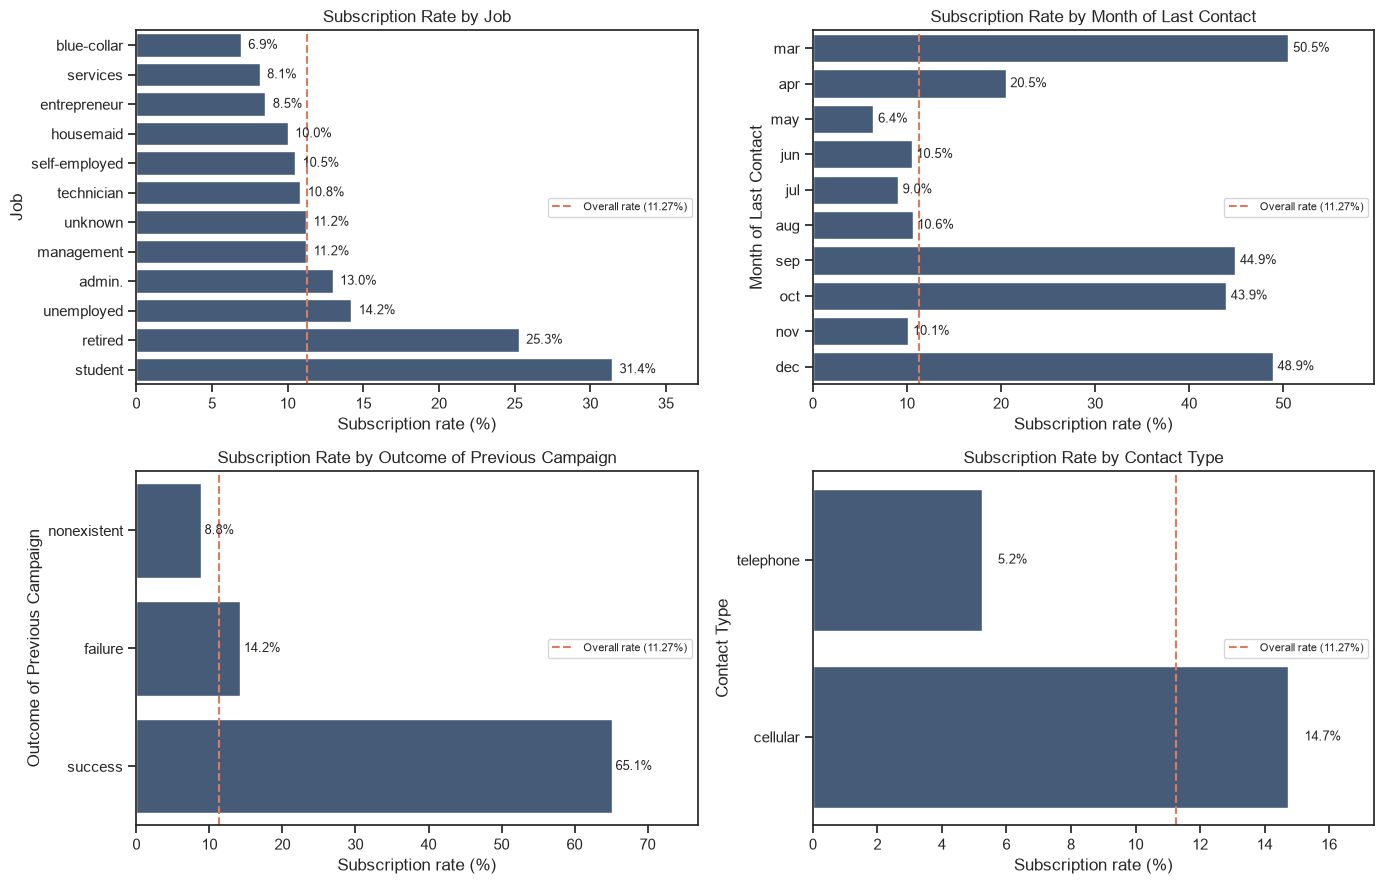

In [35]:
def bank_rate(col):
    return (bank_df.groupby(col)[BANK_TARGET].apply(lambda s: (s == "yes").mean() * 100)).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
for ax, col, title, order in [(axes[0, 0], "job", "Job", None), (axes[0, 1], "month", "Month of Last Contact", month_order),
                              (axes[1, 0], "poutcome", "Outcome of Previous Campaign", None),
                              (axes[1, 1], "contact", "Contact Type", None)]:
    rates = bank_rate(col)
    if order:
        rates = rates.reindex(order)
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color="#3d5a80", orient="h")
    for i, v in enumerate(rates.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.axvline(bank_pct["yes"], ls="--", color="#e07a5f", label=f"Overall rate ({bank_pct['yes']}%)")
    ax.set_title(f"Subscription Rate by {title}")
    ax.set_xlabel("Subscription rate (%)")
    ax.set_ylabel(title)
    ax.set_xlim(0, rates.max() * 1.18)
    ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
save(fig, "bank", "02_rate_by_category"); plt.show()

**Interpretation:**
- **Previous campaign outcome** is the strongest categorical signal: **65.1%** of customers who subscribed in a previous campaign
  (*success*) subscribed again, versus 14.2% after a *failure* and only 8.8% for customers never contacted before.
- **Month:** May has the most calls but the lowest success rate (**6.4%**), while March, September, October and December reach
  **44–51%** — these months had few, more targeted calls.
- **Job:** **students (31.4%)** and **retired** customers (25.3%) subscribe far more often than blue-collar workers (6.9%).
- **Contact type:** customers reached on a **mobile phone (14.7%)** subscribe almost three times as often as those on a landline (5.2%).

### B2c. Numerical variables vs subscription outcome
**Purpose:** compare the distribution of key numerical variables for subscribers and non-subscribers.

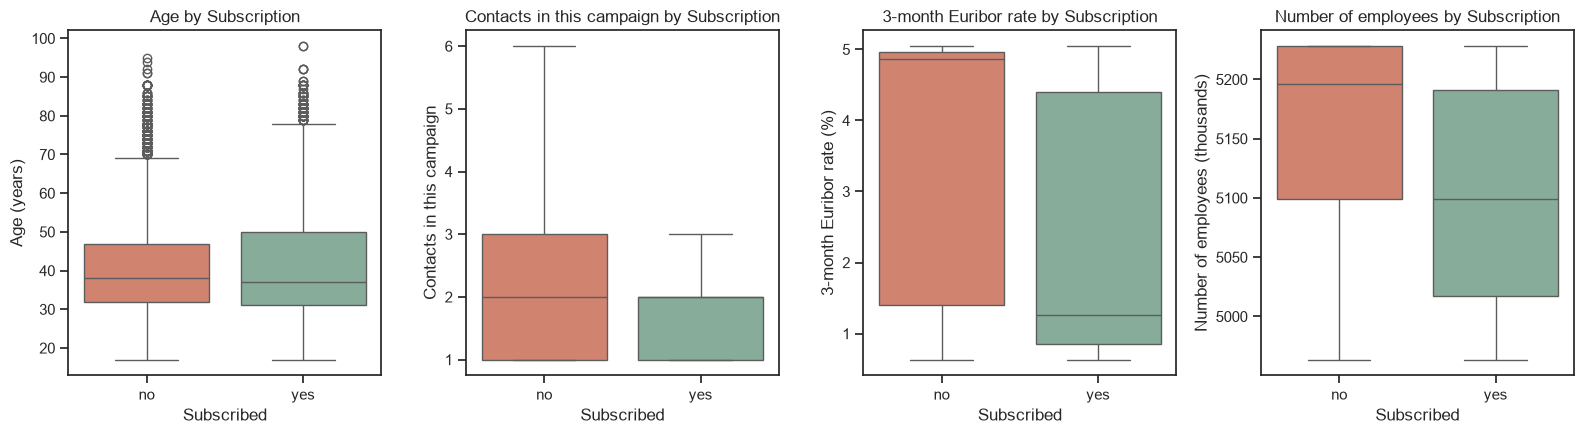

      age  campaign  euribor3m  nr.employed
y                                          
no   38.0       2.0      4.857       5195.8
yes  37.0       2.0      1.266       5099.1


In [36]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col, label in zip(axes, ["age", "campaign", "euribor3m", "nr.employed"],
                          ["Age (years)", "Contacts in this campaign", "3-month Euribor rate (%)", "Number of employees (thousands)"]):
    sns.boxplot(data=bank_df, x=BANK_TARGET, y=col, order=["no", "yes"], ax=ax, palette=["#e07a5f", "#81b29a"],
                showfliers=(col != "campaign"))
    ax.set_title(f"{label.split(' (')[0]} by Subscription")
    ax.set_xlabel("Subscribed")
    ax.set_ylabel(label)
plt.tight_layout()
save(fig, "bank", "03_numeric_boxplots"); plt.show()
print(bank_df.groupby(BANK_TARGET)[["age", "campaign", "euribor3m", "nr.employed"]].median())

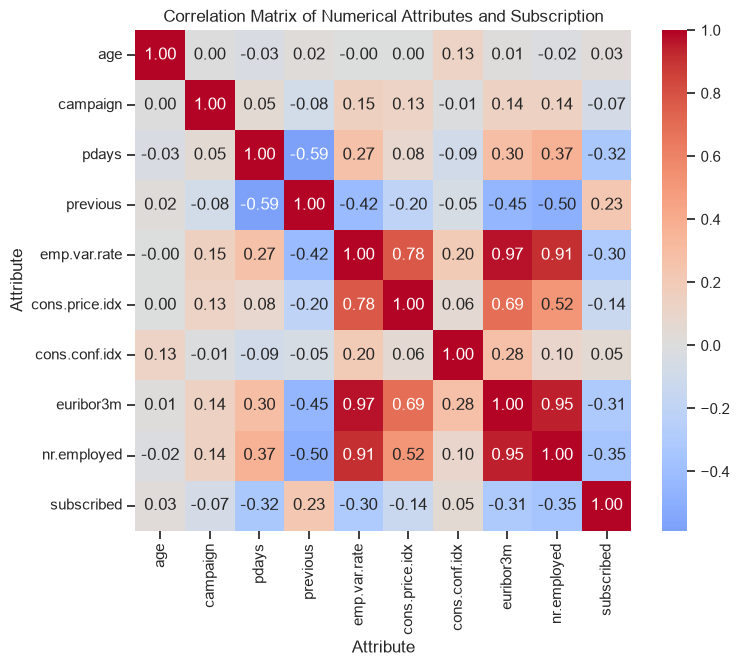

nr.employed      -0.354669
pdays            -0.324948
euribor3m        -0.307740
emp.var.rate     -0.298289
cons.price.idx   -0.136134
campaign         -0.066361
age               0.030381
cons.conf.idx     0.054802
previous          0.230202
Name: subscribed, dtype: float64

In [37]:
bank_corr = bank_df[BANK_NUM].assign(subscribed=bank_y).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(bank_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix of Numerical Attributes and Subscription")
ax.set_xlabel("Attribute")
ax.set_ylabel("Attribute")
save(fig, "bank", "04_correlation"); plt.show()
bank_corr["subscribed"].drop("subscribed").sort_values()

**Interpretation:**
- **Economic context dominates:** subscribers were called when the **Euribor rate was much lower** (median 1.27% vs 4.86%) and
  employment was lower (median 5,099 vs 5,196 thousand employees). `nr.employed` (−0.36), `euribor3m` (−0.31) and `emp.var.rate`
  (−0.30) have the strongest correlations with subscription: when interest rates and employment fall, safe term deposits become more attractive.
- **Campaign intensity:** subscribers needed fewer calls (mean 2.05 vs 2.63). Customers called more than five times subscribed only
  5.5% of the time versus 13.0% for those called once — repeated calls show diminishing returns.
- **Age:** medians are similar (37 vs 38), but the subscriber distribution is wider; customers aged 60+ subscribe at **39.6%**.
- `pdays` (−0.33) and `previous` (+0.23) confirm that prior contact with the bank matters. The economic indicators are strongly
  correlated with each other (e.g. euribor3m vs emp.var.rate 0.97), so they carry overlapping information.

### B2d. Three key observations
1. **Prior relationship matters most among customer attributes** — customers who subscribed in a previous campaign are about
   6 times more likely to subscribe (65.1% vs 11.3% overall).
2. **Timing and economic conditions strongly influence success** — subscription rates are 5× higher when the 3-month Euribor rate is
   below 2% (24.5%) than when it is 4% or more (4.8%), and May, the busiest month, has the lowest success rate (6.4%).
3. **Who and how you call matters** — students and retired customers and those reached by mobile phone subscribe most often, while
   calling the same customer many times yields diminishing returns.

## B3. Classification Model Development
**Purpose:** train the four required algorithms on the **same training data** and evaluate them on the **same test data**.
Each model is wrapped in a pipeline with the preprocessor from B1e, so all four receive identical inputs.

| Model | Settings | Reason |
|---|---|---|
| Logistic Regression | `max_iter=1000` | Linear, interpretable baseline |
| Decision Tree | `max_depth=6` | Limits tree depth to prevent overfitting (an unrestricted tree memorises the training data) |
| K-Nearest Neighbours | `n_neighbors=5` | Default k; predicts from the 5 most similar customers |
| Random Forest | `n_estimators=300, min_samples_leaf=5` | Averages 300 trees for stable, non-linear predictions |

In [38]:
bank_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
}
bank_results, bank_cms, bank_probas, bank_fitted = [], {}, {}, {}

for name, estimator in bank_models.items():
    pipe = Pipeline([("preprocessor", bank_preprocessor), ("classifier", estimator)])
    pipe.fit(bank_X_train, bank_y_train)                      # 1. train
    pred = pipe.predict(bank_X_test)                          # 2. predict
    proba = pipe.predict_proba(bank_X_test)[:, 1]
    bank_results.append({                                     # 3. metrics
        "Model": name,
        "Accuracy": accuracy_score(bank_y_test, pred),
        "Precision": precision_score(bank_y_test, pred),
        "Recall": recall_score(bank_y_test, pred),
        "F1-score": f1_score(bank_y_test, pred),
        "ROC-AUC": roc_auc_score(bank_y_test, proba),
    })
    bank_cms[name] = confusion_matrix(bank_y_test, pred)      # 4. confusion matrix
    bank_probas[name], bank_fitted[name] = proba, pipe
    print(f"=== {name} ===")
    print(classification_report(bank_y_test, pred, target_names=["no", "yes"], digits=3))

=== Logistic Regression ===
              precision    recall  f1-score   support

          no      0.909     0.983     0.945      7308
         yes      0.636     0.227     0.335       928

    accuracy                          0.898      8236
   macro avg      0.772     0.605     0.640      8236
weighted avg      0.878     0.898     0.876      8236



=== Decision Tree ===
              precision    recall  f1-score   support

          no      0.916     0.975     0.945      7308
         yes      0.600     0.300     0.400       928

    accuracy                          0.899      8236
   macro avg      0.758     0.637     0.672      8236
weighted avg      0.881     0.899     0.883      8236



=== KNN ===
              precision    recall  f1-score   support

          no      0.915     0.966     0.940      7308
         yes      0.526     0.297     0.380       928

    accuracy                          0.891      8236
   macro avg      0.721     0.632     0.660      8236
weighted avg      0.872     0.891     0.877      8236



=== Random Forest ===
              precision    recall  f1-score   support

          no      0.911     0.981     0.945      7308
         yes      0.623     0.244     0.350       928

    accuracy                          0.898      8236
   macro avg      0.767     0.612     0.647      8236
weighted avg      0.878     0.898     0.878      8236



**Observation:** all four models reach about **90% accuracy** (89.6–90.0%), yet their recall for the *yes* class is only about **21–31%** at the
default 0.5 threshold — they correctly reject most non-subscribers but miss most subscribers. This is the typical behaviour of
classifiers trained on imbalanced data and shows why accuracy alone is not a valid selection criterion.

**Overfitting check for the Decision Tree:** the cell below compares the depth-limited tree with an unrestricted one.

In [39]:
for depth in [None, 6]:
    tree = Pipeline([("preprocessor", bank_preprocessor),
                     ("classifier", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))]).fit(bank_X_train, bank_y_train)
    print(f"max_depth={depth}: train accuracy={tree.score(bank_X_train, bank_y_train):.3f}, "
          f"test accuracy={tree.score(bank_X_test, bank_y_test):.3f}, "
          f"test ROC-AUC={roc_auc_score(bank_y_test, tree.predict_proba(bank_X_test)[:, 1]):.3f}")

max_depth=None: train accuracy=0.995, test accuracy=0.841, test ROC-AUC=0.631


max_depth=6: train accuracy=0.905, test accuracy=0.899, test ROC-AUC=0.791


**Observation:** the unrestricted tree fits the training data almost perfectly but generalises poorly (test ROC-AUC ≈ 0.63), while
the depth-6 tree loses some training accuracy but ranks customers far better (≈ 0.80). This justifies limiting the depth.

## B4. Model Performance Comparison and Visualisation
### B4a. Comparison table

In [40]:
bank_table = pd.DataFrame(bank_results).set_index("Model")
bank_table.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8983,0.6355,0.2274,0.3349,0.7973
Decision Tree,0.8986,0.6004,0.2996,0.3997,0.7906
KNN,0.8906,0.5257,0.2974,0.3799,0.7290
Random Forest,0.8981,0.6226,0.2435,0.3501,0.8006


### B4b. Grouped bar chart of the evaluation metrics

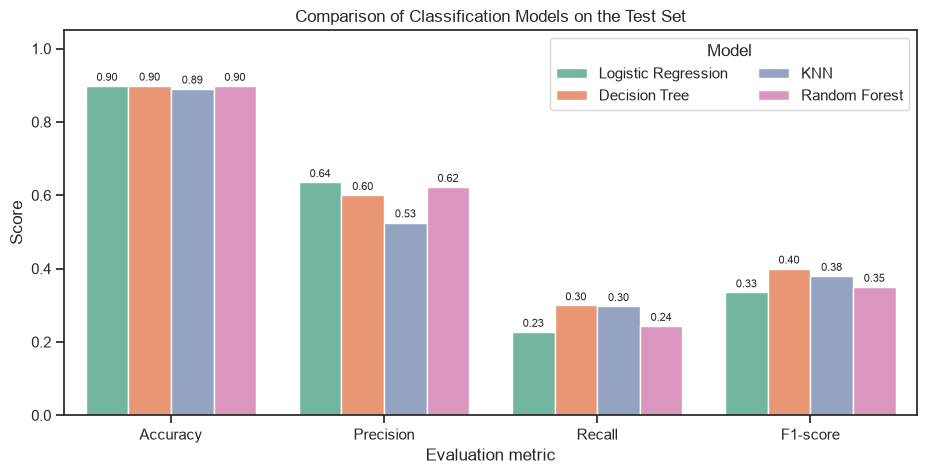

In [41]:
plot_df = bank_table[["Accuracy", "Precision", "Recall", "F1-score"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", ax=ax, palette="Set2")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Comparison of Classification Models on the Test Set")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(title="Model", loc="upper right", ncol=2)
save(fig, "bank", "05_model_comparison"); plt.show()

**Interpretation:** accuracy bars are almost identical (0.896–0.900), so accuracy cannot separate the models. **Precision** is highest
for Logistic Regression, the Decision Tree and Random Forest (≈0.65): when they predict *yes*, roughly two out of three customers
really subscribe. **KNN** has the highest **recall (0.31)** and **F1-score (0.40)** at the default threshold but lower precision (0.57).

### B4c. Confusion matrices

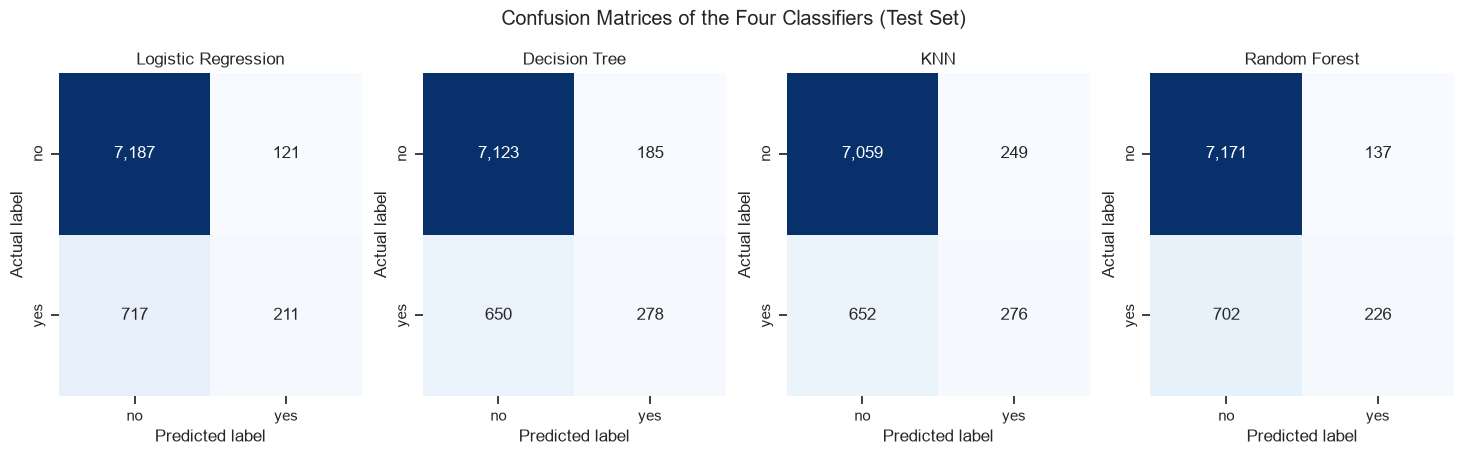

Logistic Regression  TN= 7187  FP= 121  FN= 717  TP= 211
Decision Tree        TN= 7123  FP= 185  FN= 650  TP= 278
KNN                  TN= 7059  FP= 249  FN= 652  TP= 276
Random Forest        TN= 7171  FP= 137  FN= 702  TP= 226


In [42]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, cm_) in zip(axes, bank_cms.items()):
    sns.heatmap(cm_, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
fig.suptitle("Confusion Matrices of the Four Classifiers (Test Set)", y=1.03)
save(fig, "bank", "06_confusion_matrices"); plt.show()
for name, cm_ in bank_cms.items():
    tn, fp, fn, tp = cm_.ravel()
    print(f"{name:20s} TN={tn:5d}  FP={fp:4d}  FN={fn:4d}  TP={tp:4d}")

**Interpretation of classification errors** (the test set contains 928 actual subscribers and 7,308 non-subscribers):
- **False negatives** (subscribers predicted as *no*) are the dominant error for every model — **641 (KNN) to 733 (Logistic
  Regression)** of the 928 subscribers are missed. For the bank these are *lost sales*: customers who would have said yes are never called.
- **False positives** (non-subscribers predicted as *yes*) are few — **105 to 219** — and cost only a wasted phone call.
- **KNN** finds the most subscribers (287 TP) at the price of the most false positives (219); the **Decision Tree** and **Random Forest**
  find 220–224 subscribers with about 120 false positives; **Logistic Regression** is the most conservative (195 TP, 105 FP).

### B4d. ROC curves and ROC-AUC
**Purpose:** ROC curves evaluate each model across *all* thresholds, independent of the default 0.5 cut-off.

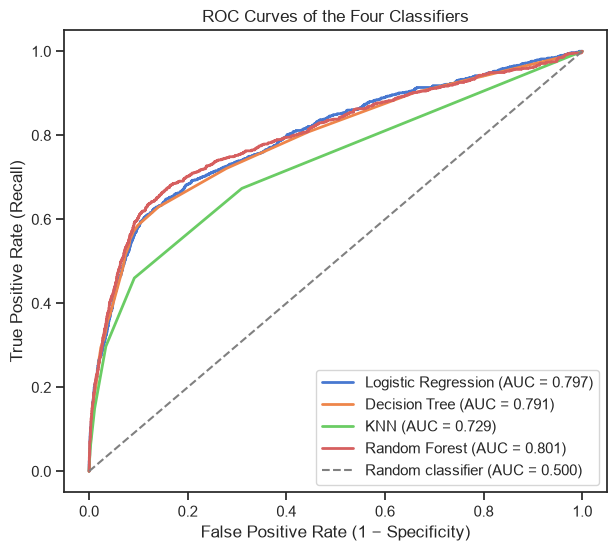

Model
Random Forest          0.8006
Logistic Regression    0.7973
Decision Tree          0.7906
KNN                    0.7290
Name: ROC-AUC, dtype: float64

In [43]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in bank_probas.items():
    fpr_, tpr_, _ = roc_curve(bank_y_test, proba)
    ax.plot(fpr_, tpr_, lw=2, label=f"{name} (AUC = {roc_auc_score(bank_y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random classifier (AUC = 0.500)")
ax.set_title("ROC Curves of the Four Classifiers")
ax.set_xlabel("False Positive Rate (1 − Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
save(fig, "bank", "07_roc_curves"); plt.show()
bank_table["ROC-AUC"].sort_values(ascending=False).round(4)

**Interpretation:** **Random Forest has the highest ROC-AUC (0.801)**, closely followed by Logistic Regression (0.797) and the Decision
Tree (0.791); KNN is lower (0.729). An AUC of 0.801 means that, for a randomly chosen subscriber and non-subscriber, Random
Forest gives the subscriber a higher score 80.1% of the time. Its curve is the highest over most of the range, so it is the best at
*ranking* customers by their likelihood of subscribing — exactly what a bank needs to decide whom to call first.

### B4e. Identifying actual subscribers – threshold analysis
**Purpose:** all models use a 0.5 probability threshold by default, which is too strict when only 11% of customers subscribe.
Because Random Forest ranks customers best, we examine how lowering its threshold changes the balance between finding subscribers
(recall) and avoiding wasted calls (precision).

 Threshold  Customers to call  Precision  Recall  F1-score
      0.50                363      0.623   0.244     0.350
      0.40                590      0.564   0.359     0.439
      0.30                945      0.491   0.500     0.495
      0.20               1238      0.446   0.595     0.510
      0.15               1410      0.410   0.623     0.494
      0.10               2007      0.319   0.691     0.437


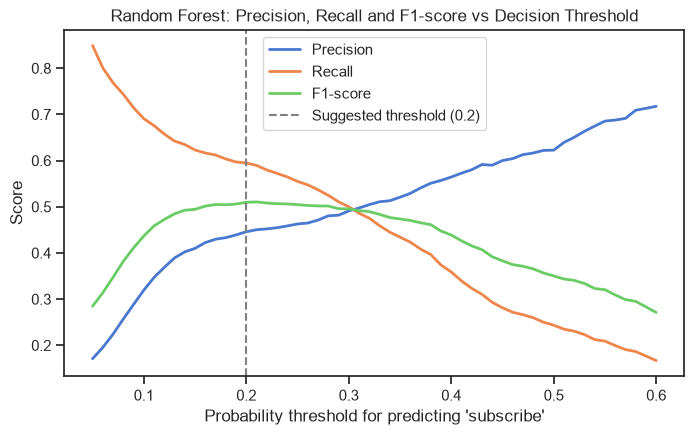

In [44]:
bank_best = "Random Forest"
bank_best_proba = bank_probas[bank_best]
bank_thresholds = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    pred_t = (bank_best_proba >= t).astype(int)
    bank_thresholds.append({"Threshold": t, "Customers to call": int(pred_t.sum()),
                            "Precision": precision_score(bank_y_test, pred_t), "Recall": recall_score(bank_y_test, pred_t),
                            "F1-score": f1_score(bank_y_test, pred_t)})
bank_thr_df = pd.DataFrame(bank_thresholds)
print(bank_thr_df.round(3).to_string(index=False))

grid = np.linspace(0.05, 0.6, 56)
fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, fn_ in [("Precision", precision_score), ("Recall", recall_score), ("F1-score", f1_score)]:
    ax.plot(grid, [fn_(bank_y_test, (bank_best_proba >= t).astype(int)) for t in grid], lw=2, label=metric)
ax.axvline(0.2, ls="--", color="grey", label="Suggested threshold (0.2)")
ax.set_title("Random Forest: Precision, Recall and F1-score vs Decision Threshold")
ax.set_xlabel("Probability threshold for predicting 'subscribe'")
ax.set_ylabel("Score")
ax.legend()
save(fig, "bank", "08_threshold_analysis"); plt.show()

**Interpretation:** lowering the Random Forest threshold from 0.5 to **0.2** raises **recall from 0.24 to 0.61** — the model now finds
about 6 out of 10 subscribers — while precision falls only from 0.65 to 0.46, and the **F1-score rises to about 0.53**, higher than any
model at the default threshold. A threshold around 0.2–0.3 is therefore a much better operating point for the bank.

### B4f. Cumulative gains – value for campaign targeting
**Purpose:** show what share of all subscribers the bank would reach if it called only the customers ranked highest by each model.

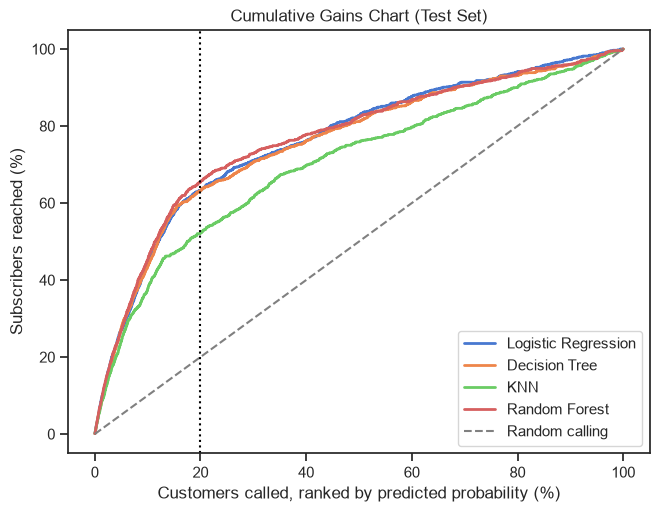

Calling the top 20% ranked by Random Forest: reaches 65.5% of subscribers, conversion rate 36.9% (vs 11.3% for random calls)


In [45]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
pct_called = np.arange(1, len(bank_y_test) + 1) / len(bank_y_test)
for name, proba in bank_probas.items():
    order = np.argsort(-proba)
    ax.plot(pct_called * 100, np.cumsum(bank_y_test.values[order]) / bank_y_test.sum() * 100, lw=2, label=name)
ax.plot([0, 100], [0, 100], "--", color="grey", label="Random calling")
ax.axvline(20, ls=":", color="black")
ax.set_title("Cumulative Gains Chart (Test Set)")
ax.set_xlabel("Customers called, ranked by predicted probability (%)")
ax.set_ylabel("Subscribers reached (%)")
ax.legend(loc="lower right")
save(fig, "bank", "09_cumulative_gains"); plt.show()

order = np.argsort(-bank_best_proba)
top20 = order[: int(0.2 * len(order))]
bank_top20_capture = bank_y_test.values[top20].sum() / bank_y_test.sum()
bank_top20_rate = bank_y_test.values[top20].mean()
print(f"Calling the top 20% ranked by {bank_best}: reaches {bank_top20_capture:.1%} of subscribers, "
      f"conversion rate {bank_top20_rate:.1%} (vs {bank_y_test.mean():.1%} for random calls)")

**Interpretation:** if the bank called only the **20% of customers ranked highest by Random Forest**, it would reach about **66% of
all subscribers**, with a conversion rate of about **37%** instead of 11% for random calling — more than three times as efficient.
Random Forest, Logistic Regression and the Decision Tree give similar gains, while KNN is noticeably weaker.

### B4g. Which attributes drive the Random Forest?

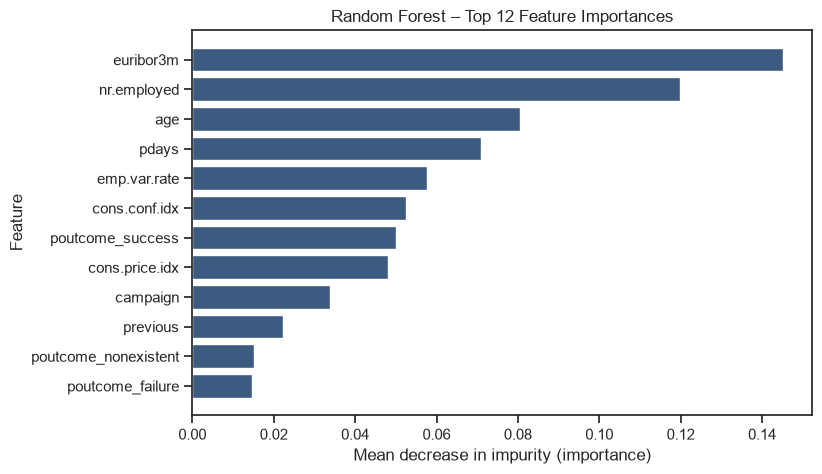

euribor3m           0.145
nr.employed         0.120
age                 0.080
pdays               0.071
emp.var.rate        0.058
cons.conf.idx       0.053
poutcome_success    0.050
cons.price.idx      0.048
campaign            0.034
previous            0.022
dtype: float64

In [46]:
rf_pipe = bank_fitted[bank_best]
bank_importance = pd.Series(rf_pipe.named_steps["classifier"].feature_importances_,
                            index=[n.split("__")[1] for n in rf_pipe.named_steps["preprocessor"].get_feature_names_out()]
                            ).sort_values(ascending=False)
top = bank_importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#3d5a80")
ax.set_title("Random Forest – Top 12 Feature Importances")
ax.set_xlabel("Mean decrease in impurity (importance)")
ax.set_ylabel("Feature")
save(fig, "bank", "10_feature_importance"); plt.show()
bank_importance.head(10).round(3)

**Interpretation:** the most important inputs are the economic indicators **euribor3m** and **nr.employed**, followed by **age**,
**pdays** and **poutcome = success**. This matches the EDA: the economic climate at the time of the call and the customer's previous
relationship with the bank are the strongest predictors of subscription.

### B4h. Best-performing model
| Criterion | Best model |
|---|---|
| ROC-AUC (ranking quality) | **Random Forest (0.801)** |
| Precision | Logistic Regression / Decision Tree / Random Forest (≈0.62) |
| Recall and F1 at threshold 0.5 | Decision Tree / Random Forest (≈0.30 / 0.40) |
| F1 after threshold tuning | **Random Forest (≈0.52 at 0.2)** |

**Selected model: Random Forest.** It achieves the highest ROC-AUC, solid precision, and — because it ranks customers best — its threshold can
be lowered to recover most subscribers while keeping precision acceptable, giving the best F1-score overall.

## B5. Interpretation and Business Recommendations
### Why Random Forest suits the bank's problem
- **Best ranking of customers** (highest ROC-AUC), which is exactly how a call list is built: call the most likely subscribers first.
- **Handles mixed data and non-linear effects** — e.g. the step-like effect of interest rates and months, and interactions such as age × job —
  without manual feature engineering, and is robust to outliers such as very high `campaign` values.
- **Stable and less prone to overfitting** than a single decision tree because it averages 300 trees.
- **Explainable at a high level** through feature importances, which agree with the EDA.
- In this business the cost of a **false negative (a lost sale)** is much higher than a **false positive (one extra call)**, so a model
  that allows recall to be raised by adjusting the threshold is preferable to one chosen purely by accuracy.

### Business recommendations
1. **Rank and prioritise customers:** score every customer with the Random Forest model before a campaign and call them in order of
   predicted probability. Calling the top 20% reaches about two-thirds of likely subscribers at roughly three times the conversion rate.
2. **Use a lower decision threshold (≈0.2–0.3):** this captures about 50–60% of subscribers instead of 24%, at the cost of moderately
   more calls — worthwhile because a missed subscriber is a lost sale.
3. **Target high-value segments and time campaigns well:** prioritise customers with a previous successful outcome, students, retired
   customers and mobile-phone contacts; run campaigns when interest rates are low, and avoid over-calling — limit repeated calls to
   about three per customer.

### Limitations
1. **Class imbalance and threshold:** with only 11% subscribers, all models are biased towards predicting *no* at the 0.5 threshold.
   The reported precision/recall depend heavily on the chosen threshold; techniques such as class weighting, resampling (SMOTE) or
   cost-sensitive learning were not explored and could change the ranking of the models.
2. **Dependence on economic indicators and time period:** the strongest predictors are macro-economic (Euribor rate, employment) from
   2008–2010, a period of financial crisis. If economic conditions change, the model may not generalise and would need retraining;
   moreover, the random split mixes time periods, so the test score may be optimistic compared with predicting a future campaign.
3. **Limited tuning:** hyperparameters were set to reasonable values rather than tuned by cross-validation, so each model's
   performance — especially KNN's — may not be its best possible.

### Saving Part B results
**Purpose:** store the metrics, confusion matrices and threshold analysis for use in the written report.

In [47]:
with open(MODEL_DIR / "bank_metrics.json", "w") as f:
    json.dump({
        "table": bank_table.round(4).reset_index().to_dict(orient="records"),
        "confusion_matrices": {k: v.tolist() for k, v in bank_cms.items()},
        "thresholds": bank_thr_df.round(4).to_dict(orient="records"),
        "top20_capture": round(float(bank_top20_capture), 4), "top20_rate": round(float(bank_top20_rate), 4),
        "importance": bank_importance.head(10).round(4).to_dict(),
        "n_rows": int(len(bank_df)), "n_train": int(len(bank_X_train)), "n_test": int(len(bank_X_test)),
        "n_features_encoded": int(bank_X_train_enc.shape[1]),
    }, f, indent=2)
print("Saved model/bank_metrics.json")

Saved model/bank_metrics.json


# Overall Conclusion
- **Part A** showed that a single, interpretable **logistic regression** model predicts Titanic survival with ≈84.4% accuracy and 0.898
  ROC-AUC, and that **sex, passenger class and age** decided who survived. The model was deployed as a Streamlit app (`app.py`).
- **Part B** compared **four classifiers** on the imbalanced bank-marketing data. Accuracy was nearly identical for all of them, so
  the comparison relied on precision, recall, F1-score and ROC-AUC. **Random Forest** ranked customers best (ROC-AUC 0.801) and, with a
  tuned threshold, found about 60% of subscribers; calling its top-ranked 20% of customers would reach over 60% of all subscribers.
- Together, the two studies demonstrate the full data-science workflow — understanding and cleaning data, exploratory analysis,
  modelling, choosing metrics that fit the problem, interpreting results and turning them into practical decisions.